# Consultas y bibliotecas

Consultas 1 a 17 sobre la base de datos de elementos transponibles (TEs) en MongoDB.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve()))  # para poder hacer "from pipeline.limpiar import clave"

import pandas as pd
from IPython.display import display
from pymongo import MongoClient

# Conexión a la base ya cargada (NO usar setup_database con drop_existing=True: borraría las colecciones)
MONGO_URI = "mongodb://localhost:27017"  # ajusta si tu Mongo no es local
NOMBRE_DB = "panteon"

client = MongoClient(MONGO_URI)
db = client[NOMBRE_DB]

# Verificación rápida
print(db.list_collection_names())
print("sequences:", db.sequences.count_documents({}), "| species:", db.species.count_documents({}))

['sequences', 'species']
sequences: 239946 | species: 2790


## Bloque 1: Cantidad de elementos (Consultas 1 a 4)

### Consulta 1
¿Cuántos TEs hay por clase, por orden y por superfamilia en toda la base?

In [2]:
# 1A. Conteo por Clase de TE
pipeline_q1_clase = [
    {"$group": {"_id": "$te_class", "total_tes": {"$sum": 1}}},
    {"$sort": {"total_tes": -1}}
]
df_q1_clase = pd.DataFrame(list(db.sequences.aggregate(pipeline_q1_clase)))
display(df_q1_clase)

# 1B. Conteo por Orden de TE
pipeline_q1_orden = [
    {"$group": {"_id": "$te_order", "total_tes": {"$sum": 1}}},
    {"$sort": {"total_tes": -1}}
]
df_q1_orden = pd.DataFrame(list(db.sequences.aggregate(pipeline_q1_orden)))
display(df_q1_orden)

# 1C. Conteo por Superfamilia de TE (aquí sí usamos json_normalize porque _id es un diccionario)
pipeline_q1_superfamilia = [
    {"$group": {
        "_id": {
            "clase": "$te_class",
            "orden": "$te_order",
            "superfamilia": "$te_superfamily"
        },
        "total_tes": {"$sum": 1}
    }},
    {"$sort": {"total_tes": -1}}
]
df_q1_super = pd.json_normalize(list(db.sequences.aggregate(pipeline_q1_superfamilia)))
display(df_q1_super.head(15))

,_id,total_tes
0,CLASSI,194774
1,CLASSII,45172


,_id,total_tes
0,LTR,119368
1,LINE,68382
2,TIR,36471
3,HELITRON,5075
4,SINE,3634
5,MITE,3456
6,DIRS,2933
7,PLE,344
8,RETROPOSON,113
9,CRYPTON,112


,total_tes,_id.clase,_id.orden,_id.superfamilia
0,50849,CLASSI,LTR,COPIA
1,43963,CLASSI,LTR,GYPSY
2,23821,CLASSI,LINE,L1
3,12202,CLASSI,LTR,ERV
4,11234,CLASSI,LINE,CR1
5,10962,CLASSI,LINE,L2
6,10729,CLASSII,TIR,TC1MARINER
7,10648,CLASSII,TIR,HAT
8,5983,CLASSII,TIR,TIR
9,5143,CLASSI,LINE,RTE


**Interpretación:** La base está dominada por la clase CLASSI, con 194.774 secuencias (81,17 %), frente a 45.172 de CLASSII (18,83 %). Por orden, LTR (119.368; 49,75 %) y LINE (68.382; 28,50 %) concentran casi el 78 % del total, seguidos de TIR (36.471; 15,20 %), mientras que órdenes como CRYPTON (112) y MAVERICK (58) son marginales.

Esto tiene sentido biológico: los retrotransposones (clase I) se mueven por "copiar y pegar" a través de un intermediario de ARN, así que pueden acumular miles de copias sin perder la original, mientras que los transposones de ADN (clase II) suelen "cortar y pegar". En MongoDB el conteo se resuelve con el índice compuesto `idx_te_hierarchy` (te_class, te_order, te_superfamily).

### Consulta 2
¿Cuántos TEs tiene cada especie, desglosados por clase, orden y superfamilia?

In [3]:
pipeline_q2 = [
    {"$group": {
        "_id": {
            "species_key": "$species_key",
            "te_class": "$te_class",
            "te_order": "$te_order",
            "te_superfamily": "$te_superfamily"
        },
        "cantidad_tes": {"$sum": 1}
    }},
    {"$sort": {"_id.species_key": 1, "cantidad_tes": -1}}
]

res_q2 = list(db.sequences.aggregate(pipeline_q2))
# Aplanamos el diccionario _id para verlo limpio en un DataFrame
df_q2 = pd.json_normalize(res_q2)
display(df_q2.head(15))

,cantidad_tes,_id.species_key,_id.te_class,_id.te_order,_id.te_superfamily
0,1,abortiporus biennis,CLASSI,LTR,BELPAO
1,58,abrus pulchellus subsp cantoniensis,CLASSI,LTR,GYPSY
2,58,abrus pulchellus subsp cantoniensis,CLASSI,LTR,COPIA
3,18,abrus pulchellus subsp cantoniensis,CLASSI,LTR,CAULIMOVIRUS
4,14,abrus pulchellus subsp cantoniensis,CLASSII,TIR,HAT
5,8,abrus pulchellus subsp cantoniensis,CLASSII,TIR,CMC
6,7,abrus pulchellus subsp cantoniensis,CLASSII,TIR,MULE
7,7,abrus pulchellus subsp cantoniensis,CLASSI,LINE,L1
8,3,abrus pulchellus subsp cantoniensis,CLASSII,HELITRON,HELITRON
9,3,abrus pulchellus subsp cantoniensis,CLASSI,LTR,LARD


**Interpretación:** La diversidad interna varía mucho entre especies. El hongo Abortiporus biennis y Absidia glauca tienen apenas 1 secuencia de una sola superfamilia (BELPAO y RTE, respectivamente), mientras que la planta Abrus pulchellus subsp. cantoniensis presenta varias superfamilias, encabezadas por COPIA (58) y GYPSY (58). Además, usar `species_key` normalizada permitió agrupar correctamente subespecies cuyo nombre variaba solo en la puntuación (subsp. vs subsp).

### Consulta 3
¿Cómo cambia la cantidad de TEs por clase y orden entre reinos (Animalia, Plantae, Fungi)? ¿Y entre phyla?

In [4]:
# 3A. Cantidad de TEs por Clase y Orden entre Reinos (Kingdom)
pipeline_q3_reino = [
    # Paso 1: Pre-agrupar en sequences por especie, clase y orden para reducir volumen
    {"$group": {
        "_id": {
            "species_key": "$species_key",
            "te_class": "$te_class",
            "te_order": "$te_order"
        },
        "conteo_especie": {"$sum": 1}
    }},
    # Paso 2: Cruzar con la colección species usando el índice único species_key
    {"$lookup": {
        "from": "species",
        "localField": "_id.species_key",
        "foreignField": "species_key",
        "as": "sp_info"
    }},
    {"$unwind": "$sp_info"},
    # Paso 3: Agrupar finalmente por Reino (Kingdom), te_class y te_order
    {"$group": {
        "_id": {
            "Kingdom": "$sp_info.Kingdom",
            "te_class": "$_id.te_class",
            "te_order": "$_id.te_order"
        },
        "total_tes": {"$sum": "$conteo_especie"}
    }},
    {"$sort": {"_id.Kingdom": 1, "total_tes": -1}}
]

df_q3_reino = pd.json_normalize(list(db.sequences.aggregate(pipeline_q3_reino)))
display(df_q3_reino)

# 3B. Cantidad de TEs por Clase y Orden entre Phyla (Phylum)
pipeline_q3_phylum = [
    {"$group": {
        "_id": {
            "species_key": "$species_key",
            "te_class": "$te_class",
            "te_order": "$te_order"
        },
        "conteo_especie": {"$sum": 1}
    }},
    {"$lookup": {
        "from": "species",
        "localField": "_id.species_key",
        "foreignField": "species_key",
        "as": "sp_info"
    }},
    {"$unwind": "$sp_info"},
    {"$group": {
        "_id": {
            "Phylum": "$sp_info.Phylum",
            "te_class": "$_id.te_class",
            "te_order": "$_id.te_order"
        },
        "total_tes": {"$sum": "$conteo_especie"}
    }},
    {"$sort": {"total_tes": -1}}
]

df_q3_phylum = pd.json_normalize(list(db.sequences.aggregate(pipeline_q3_phylum)))
display(df_q3_phylum.head(15))

,total_tes,_id.Kingdom,_id.te_class,_id.te_order
0,44477,Animalia,CLASSI,LINE
1,25382,Animalia,CLASSI,LTR
2,21659,Animalia,CLASSII,TIR
3,3091,Animalia,CLASSI,SINE
4,2718,Animalia,CLASSII,MITE
5,2125,Animalia,CLASSI,DIRS
6,1167,Animalia,CLASSII,HELITRON
7,257,Animalia,CLASSI,PLE
8,113,Animalia,CLASSI,RETROPOSON
9,112,Animalia,CLASSII,CRYPTON


,total_tes,_id.Phylum,_id.te_class,_id.te_order
0,84523,Angiosperma,CLASSI,LTR
1,22638,Chordata,CLASSI,LINE
2,18756,Chordata,CLASSI,LTR
3,17265,Angiosperma,CLASSI,LINE
4,16584,Chordata,CLASSII,TIR
5,15318,Arthropoda,CLASSI,LINE
6,11407,Angiosperma,CLASSII,TIR
7,5070,Arthropoda,CLASSI,LTR
8,4040,Ascomycota,CLASSI,LTR
9,3459,Ascomycota,CLASSI,LINE


**Interpretación:** El orden dominante cambia según el reino:

- **Plantae:** LTR domina ampliamente con 86.049 secuencias, frente a 17.768 LINE y 11.749 TIR.
- **Animalia:** el más abundante es LINE (44.477), seguido de LTR (25.382) y TIR (21.659). Este reino concentra casi todos los SINE (3.091) y la totalidad de RETROPOSON (113) y CRYPTON (112).
- **Fungi:** aunque tiene más especies en el CSV (1.559), suma muchas menos secuencias, lideradas por LTR (7.937) y LINE (6.137).

Esto refleja un patrón conocido: los genomas de plantas suelen expandirse por retrotransposones LTR, mientras que en animales los elementos no-LTR (LINE y SINE) son muy activos. Técnicamente, pre-agrupar en `sequences` antes del `$lookup` evitó cruzar los 239.946 documentos uno por uno.

### Consulta 4
¿Cuáles son las 10 especies con más TEs y las 10 con menos?

In [5]:
def top_especies(orden=-1, limite=10):
    pipeline = [
        {"$group": {"_id": "$species_key", "total_tes": {"$sum": 1}}},
        {"$sort": {"total_tes": orden, "_id": 1}},
        {"$limit": limite},
        {"$lookup": {
            "from": "species",
            "localField": "_id",
            "foreignField": "species_key",
            "as": "info"
        }},
        {"$unwind": "$info"},
        {"$project": {
            "_id": 0,
            "Species": "$info.Species",
            "Kingdom": "$info.Kingdom",
            "Phylum": "$info.Phylum",
            "total_tes": 1
        }}
    ]
    return pd.DataFrame(list(db.sequences.aggregate(pipeline)))

print("Top 10 especies con MÁS elementos transponibles:")
display(top_especies(orden=-1, limite=10))

print("Top 10 especies con MENOS elementos transponibles:")
display(top_especies(orden=1, limite=10))

Top 10 especies con MÁS elementos transponibles:


,total_tes,Species,Kingdom,Phylum
0,1627,Malus domestica,Plantae,Angiosperma
1,1352,Danio rerio,Animalia,Chordata
2,1294,Callithrix jacchus,Animalia,Chordata
3,1173,Homininae,Animalia,Chordata
4,1159,Nicotiana attenuata,Plantae,Angiosperma
5,1148,Colobus angolensis,Animalia,Chordata
6,1129,Chlorocebus sabaeus,Animalia,Chordata
7,1115,Geotrypetes seraphini,Animalia,Chordata
8,1103,Sitophilus oryzae,Animalia,Arthropoda
9,1090,Oryza sativa,Plantae,Angiosperma


Top 10 especies con MENOS elementos transponibles:


,total_tes,Species,Kingdom,Phylum
0,1,Abortiporus biennis,Fungi,Basidiomycota
1,1,Absidia glauca,Fungi,Mucoromycota
2,1,Achaetomium macrosporum,Fungi,Ascomycota
3,1,Acidothrix acidophila,Fungi,Ascomycota
4,1,Acropora acuminata,Animalia,Cnidaria
5,1,Acropora nasuta,Animalia,Cnidaria
6,1,Agrocybe aegerita,Fungi,Basidiomycota
7,1,Alternaria arborescens,Fungi,Ascomycota
8,1,Alternaria carthami,Fungi,Ascomycota
9,1,Alternaria gaisen,Fungi,Ascomycota


**Interpretación:** La especie con más registros es el manzano (Malus domestica, Plantae, 1.627 TEs), seguida del pez cebra (Danio rerio, Animalia, 1.352) y de varios primates y cordados, como Callithrix jacchus (1.294) y Homininae (1.173), además de plantas modelo como el arroz (Oryza sativa, 1.090). En el otro extremo, las 10 especies con menos elementos tienen exactamente 1 TE cada una y son sobre todo hongos (Ascomycota y Basidiomycota) y corales (Cnidaria).

Probablemente los organismos modelo y los cultivos de interés agronómico o biomédico tienen genomas más grandes y bibliotecas mejor anotadas, mientras que los hongos tienen genomas compactos con poca acumulación de ADN repetitivo.

## Bloque 2: Longitud y contenido GC (Consultas 5 a 7)

### Consulta 5
¿Cuál es la longitud promedio, mínima y máxima de los TEs por clase, orden y superfamilia?

In [6]:
pipeline_q5 = [
    {"$group": {
        "_id": {
            "te_class": "$te_class",
            "te_order": "$te_order",
            "te_superfamily": "$te_superfamily"
        },
        "longitud_promedio": {"$avg": "$metrics.length"},
        "longitud_minima": {"$min": "$metrics.length"},
        "longitud_maxima": {"$max": "$metrics.length"},
        "total_tes": {"$sum": 1}
    }},
    {"$project": {
        "_id": 0,
        "te_class": "$_id.te_class",
        "te_order": "$_id.te_order",
        "te_superfamily": "$_id.te_superfamily",
        "longitud_promedio": {"$round": ["$longitud_promedio", 2]},
        "longitud_minima": 1,
        "longitud_maxima": 1,
        "total_tes": 1
    }},
    {"$sort": {"te_class": 1, "te_order": 1, "longitud_promedio": -1}}
]

df_q5 = pd.DataFrame(list(db.sequences.aggregate(pipeline_q5)))
display(df_q5.head(20))

,longitud_minima,longitud_maxima,total_tes,te_class,te_order,te_superfamily,longitud_promedio
0,109,6987,2067,CLASSI,DIRS,DIRS,4772.04
1,191,6998,866,CLASSI,DIRS,NGARO,3557.88
2,515,5992,1368,CLASSI,LINE,LOA,4044.69
3,1030,5958,56,CLASSI,LINE,DUALEN,4029.30
4,503,5995,1990,CLASSI,LINE,I,3804.91
5,512,5986,1176,CLASSI,LINE,R1,3686.80
6,500,6000,23821,CLASSI,LINE,L1,3501.49
7,511,5997,1605,CLASSI,LINE,JOCKEY,3390.13
8,507,5976,1314,CLASSI,LINE,RTEX,3310.43
9,532,5940,629,CLASSI,LINE,CRE,3262.99


**Interpretación:** En las superfamilias de CLASSI mostradas, DIRS/DIRS alcanza una longitud promedio alta (4.772,04 pb; máximo de 6.987 pb). Dentro de LINE destacan LOA (4.044,69 pb), DUALEN (4.029,30 pb) y L1 (3.501,49 pb en 23.821 secuencias), con máximos cercanos a 6.000 pb y mínimos alrededor de 500 pb.

Los elementos autónomos de clase I (DIRS, LTR, LINE) deben codificar su propia maquinaria enzimática, como la transcriptasa inversa y las endonucleasas, lo que exige secuencias de varios kilobases (3 a 7 kb). Las copias de ~500 pb corresponden a versiones truncadas, producto de retrotransposiciones incompletas.

### Consulta 6
¿Cuál es el porcentaje de GC promedio por orden y por reino?

In [7]:
pipeline_q6 = [
    # Paso 1: Pre-agrupar por especie y orden de TE sumando GC y contando secuencias
    {"$group": {
        "_id": {"species_key": "$species_key", "te_order": "$te_order"},
        "suma_gc": {"$sum": "$metrics.gc_content"},
        "n_seqs": {"$sum": 1}
    }},
    # Paso 2: Cruzar con species para traer el Reino (Kingdom)
    {"$lookup": {
        "from": "species",
        "localField": "_id.species_key",
        "foreignField": "species_key",
        "as": "sp"
    }},
    {"$unwind": "$sp"},
    # Paso 3: Agrupar por Kingdom y te_order y calcular el promedio exacto
    {"$group": {
        "_id": {"Kingdom": "$sp.Kingdom", "te_order": "$_id.te_order"},
        "total_gc": {"$sum": "$suma_gc"},
        "total_seqs": {"$sum": "$n_seqs"}
    }},
    {"$project": {
        "_id": 0,
        "Kingdom": "$_id.Kingdom",
        "te_order": "$_id.te_order",
        "gc_promedio": {"$round": [{"$divide": ["$total_gc", "$total_seqs"]}, 2]},
        "total_seqs": 1
    }},
    {"$sort": {"Kingdom": 1, "gc_promedio": -1}}
]

df_q6 = pd.DataFrame(list(db.sequences.aggregate(pipeline_q6)))
display(df_q6)

,total_seqs,Kingdom,te_order,gc_promedio
0,3091,Animalia,SINE,53.66
1,2125,Animalia,DIRS,52.64
2,113,Animalia,RETROPOSON,50.80
3,25382,Animalia,LTR,47.68
4,112,Animalia,CRYPTON,45.58
5,1167,Animalia,HELITRON,43.83
6,44477,Animalia,LINE,43.40
7,2718,Animalia,MITE,42.56
8,21659,Animalia,TIR,41.85
9,43,Animalia,MAVERICK,39.52


**Interpretación:** En los tres reinos, los órdenes de clase I como DIRS (51,83 % a 53,63 %) y SINE (47,16 % a 53,66 %), además de PLE en plantas (63,28 %), tienen los contenidos de GC más altos. En cambio, los de clase II como TIR (38,36 % en plantas y 41,85 % en animales), MITE (36,74 % en plantas) y HELITRON (35,64 % en plantas) son pobres en GC, es decir, ricos en A+T.

Una posible explicación es que los transposones de ADN prefieren regiones ricas en A+T porque los pares A-T, con dos enlaces de hidrógeno, requieren menos energía para abrirse que los pares G-C, con tres, algo útil durante la escisión o la replicación por círculo rodante. Es una hipótesis que habría que contrastar con literatura.

### Consulta 7
¿Qué TEs son los más largos y los más cortos de cada reino? Muestren su nombre, clasificación y especie.

In [8]:
resultados_q7 = []

for reino in ["Animalia", "Plantae", "Fungi"]:
    # Obtenemos las claves de especies de este reino (consulta instantánea en species)
    claves_reino = db.species.distinct("species_key", {"Kingdom": reino})

    for etiqueta, orden in [("Más largo", -1), ("Más corto", 1)]:
        doc = db.sequences.find_one(
            {"species_key": {"$in": claves_reino}},
            {"_id": 0, "sequence_id": 1, "classification_raw": 1, "species_raw": 1, "metrics.length": 1},
            sort=[("metrics.length", orden)]
        )
        if doc:
            resultados_q7.append({
                "Kingdom": reino,
                "Extremo": etiqueta,
                "sequence_id": doc["sequence_id"],
                "clasificacion": doc["classification_raw"],
                "especie": doc["species_raw"],
                "longitud": doc["metrics"]["length"]
            })

df_q7 = pd.DataFrame(resultados_q7)
display(df_q7)

,Kingdom,Extremo,sequence_id,clasificacion,especie,longitud
0,Animalia,Más largo,PDB00076912,CLASSI/LTR/ERV,Aphelocoma californica,18951
1,Animalia,Más corto,AllBul-4.608,CLASSI/SINE/ID,Orientallactaga bullata,81
2,Plantae,Más largo,PDB00038441,CLASSI/LTR/GYPSY,Helianthus annuus,19926
3,Plantae,Más corto,PDB00049072,CLASSII/HELITRON/HELITRON,Oryza barthii,100
4,Fungi,Más largo,PDB00194372,CLASSI/LTR/ERV,Lactarius subdulcis,19189
5,Fungi,Más corto,PDB00183015,CLASSII/HELITRON/HELITRON,Dactylonectria macrodidyma,100


**Interpretación:** Las secuencias más largas de los tres reinos son retrotransposones CLASSI/LTR cercanos a los 19-20 kb: PDB00038441 (GYPSY en el girasol Helianthus annuus, 19.926 pb) en Plantae, PDB00194372 (ERV en Lactarius subdulcis, 19.189 pb) en Fungi y PDB00076912 (ERV en Aphelocoma californica, 18.951 pb) en Animalia. Las más cortas son elementos pequeños o no autónomos: AllBul-4.608 (CLASSI/SINE/ID, 81 pb) en Animalia y dos HELITRON de 100 pb en Plantae (PDB00049072) y Fungi (PDB00183015).

Esto muestra los dos extremos biológicos: los LTR completos pueden medir casi 20.000 nucleótidos, mientras que los SINE, que derivan de ARN pequeños como el ARNt, apenas superan los 80.

## Bloque 3: Búsqueda de secuencias y generación de bibliotecas .fasta (Consultas 8 a 11)

### Consulta 8
Buscar una secuencia por su nombre (por ejemplo, PDB00000001) y mostrar su clasificación, especie y taxonomía completa.

In [9]:
def buscar_secuencia_por_id(seq_id="PDB00000001"):
    pipeline = [
        {"$match": {"sequence_id": seq_id}},
        {"$lookup": {
            "from": "species",
            "localField": "species_key",
            "foreignField": "species_key",
            "as": "taxonomia"
        }},
        {"$unwind": "$taxonomia"},
        {"$project": {
            "_id": 0,
            "sequence_id": 1,
            "te_class": 1,
            "te_order": 1,
            "te_superfamily": 1,
            "Species": "$taxonomia.Species",
            "Kingdom": "$taxonomia.Kingdom",
            "Phylum": "$taxonomia.Phylum",
            "Class": "$taxonomia.Class",
            "Order": "$taxonomia.Order",
            "Family": "$taxonomia.Family",
            "length": "$metrics.length",
            "gc_content": "$metrics.gc_content"
        }}
    ]
    return pd.DataFrame(list(db.sequences.aggregate(pipeline)))

display(buscar_secuencia_por_id("PDB00000001"))

,sequence_id,te_class,te_order,te_superfamily,Species,Kingdom,Phylum,Class,Order,Family,length,gc_content
0,PDB00000001,CLASSII,HELITRON,HELITRON,Halicephalobus mephisto,Animalia,Nematoda,Chromadorea,Rhabditida,Panagrolaimidae,1991,31.541939


**Interpretación:** La secuencia PDB00000001 es un CLASSII/HELITRON/HELITRON de 1.991 pb y 31,54 % de GC, perteneciente al nematodo Halicephalobus mephisto (Animalia → Nematoda → Chromadorea → Rhabditida → Panagrolaimidae). La búsqueda por ID se apoya en el índice único `idx_sequence_id_unique`, por lo que devuelve el resultado sin escanear la colección.

### Consulta 9
Listar los nombres de todas las secuencias de una superfamilia en una especie dada.

In [10]:
from pipeline.limpiar import clave

def listar_secuencias_superfamilia(especie="Halicephalobus mephisto", superfamilia="HELITRON"):
    sp_key = clave(especie)
    cursor = db.sequences.find(
        {"species_key": sp_key, "te_superfamily": superfamilia.upper()},
        {"_id": 0, "sequence_id": 1, "te_class": 1, "te_order": 1, "te_superfamily": 1, "metrics.length": 1}
    )
    return pd.DataFrame(list(cursor))

df_q9 = listar_secuencias_superfamilia("Halicephalobus mephisto", "HELITRON")
print(f"Total encontradas: {len(df_q9)}")
display(df_q9.head(15))

Total encontradas: 2


,sequence_id,te_class,te_order,te_superfamily,metrics
0,PDB00000001,CLASSII,HELITRON,HELITRON,{'length': 1991}
1,PDB00000002,CLASSII,HELITRON,HELITRON,{'length': 1689}


**Interpretación:** Halicephalobus mephisto tiene en total 2 secuencias de la superfamilia HELITRON: PDB00000001 y PDB00000002 (esta última de 1.689 pb). La consulta usa el índice compuesto `idx_species_superfamily`, así que tampoco requiere recorrer la colección.

### Consulta 10
Exportar una biblioteca `.fasta` de una especie dada, directamente desde MongoDB, con el encabezado `>ID#CLASE/ORDEN/SUPERFAMILIA @Especie` y usando parámetros.

In [11]:
from pathlib import Path

CARPETA_FASTA = Path("../exports_fasta")
CARPETA_FASTA.mkdir(exist_ok=True)

# CONSULTA 10: Exportar biblioteca .fasta de una especie dada (parametrizada)
def exportar_biblioteca_especie(nombre_especie, ruta_salida=None):
    sp_key = clave(nombre_especie)
    if ruta_salida is None:
        nombre_limpio = sp_key.replace(" ", "_")
        ruta_salida = CARPETA_FASTA / f"biblioteca_especie_{nombre_limpio}.fasta"

    cursor = db.sequences.find(
        {"species_key": sp_key},
        {"_id": 0, "sequence_id": 1, "classification_raw": 1, "species_raw": 1, "sequence": 1}
    )

    conteo = 0
    with open(ruta_salida, "w", encoding="utf-8") as f:
        for doc in cursor:
            header = f">{doc['sequence_id']}#{doc['classification_raw']} @{doc['species_raw']}\n"
            f.write(header)
            f.write(f"{doc['sequence']}\n")
            conteo += 1

    print(f"[Consulta 10] Exportadas {conteo} secuencias de '{nombre_especie}' en: {ruta_salida}")
    return ruta_salida

**Interpretación:** Se generó desde MongoDB el archivo `.fasta` de la especie Halicephalobus mephisto con 10 secuencias. La función es parametrizada y usa un cursor de pymongo con proyección (`_id: 0`), escribiendo en disco en modo streaming con el encabezado `>ID#CLASE/ORDEN/SUPERFAMILIA @Especie`, sin cargar todo en memoria.

### Consulta 11
Exportar una biblioteca `.fasta` de un reino dado, directamente desde MongoDB, con el mismo formato de encabezado y usando parámetros.

In [12]:
# CONSULTA 11: Exportar biblioteca .fasta de un reino dado (parametrizada)
def exportar_biblioteca_reino(nombre_reino, limite=None, ruta_salida=None):
    if ruta_salida is None:
        ruta_salida = CARPETA_FASTA / f"biblioteca_reino_{nombre_reino.lower()}.fasta"

    # 1. Obtener todas las species_key que pertenecen al reino solicitado
    claves_reino = db.species.distinct("species_key", {"Kingdom": nombre_reino})

    # 2. Consultar secuencias filtrando por esas especies
    cursor = db.sequences.find(
        {"species_key": {"$in": claves_reino}},
        {"_id": 0, "sequence_id": 1, "classification_raw": 1, "species_raw": 1, "sequence": 1}
    )
    if limite:
        cursor = cursor.limit(limite)

    conteo = 0
    with open(ruta_salida, "w", encoding="utf-8") as f:
        for doc in cursor:
            header = f">{doc['sequence_id']}#{doc['classification_raw']} @{doc['species_raw']}\n"
            f.write(header)
            f.write(f"{doc['sequence']}\n")
            conteo += 1

    print(f"[Consulta 11] Exportadas {conteo} secuencias del reino '{nombre_reino}' en: {ruta_salida}")
    return ruta_salida

# Ejecución para generar los archivos obligatorios del Entregable 6:
exportar_biblioteca_especie("Halicephalobus mephisto")
exportar_biblioteca_reino("Plantae")  # Plantae tiene 451 especies, genera un archivo manejable

[Consulta 10] Exportadas 10 secuencias de 'Halicephalobus mephisto' en: ..\exports_fasta\biblioteca_especie_halicephalobus_mephisto.fasta
[Consulta 11] Exportadas 119005 secuencias del reino 'Plantae' en: ..\exports_fasta\biblioteca_reino_plantae.fasta


WindowsPath('../exports_fasta/biblioteca_reino_plantae.fasta')

**Interpretación:** Se exportaron 119.005 secuencias para el reino Plantae, lo que equivale al 49,60 % de toda la base de datos, a pesar de que Plantae solo representa 451 de las 2.790 especies. Al escribir con el cursor en streaming, el archivo se generó sin desbordar la memoria RAM.

## Bloque 4: Relaciones, calidad, k-mers y consultas propias (Consultas 12 a 17)

### Consulta 12
¿Cómo se puede unir explícitamente una secuencia con la taxonomía completa de su especie utilizando el operador `$lookup`?

In [13]:
pipeline_q12 = [
    {"$limit": 5},  # Muestra de 5 documentos para verificar
    {"$lookup": {
        "from": "species",
        "localField": "species_key",
        "foreignField": "species_key",
        "as": "taxonomia_especie"
    }},
    {"$unwind": "$taxonomia_especie"},
    {"$project": {
        "_id": 0,
        "sequence_id": 1,
        "te_class": 1,
        "especie": "$species_raw",
        "reino": "$taxonomia_especie.Kingdom",
        "phylum": "$taxonomia_especie.Phylum"
    }}
]
df_q12 = pd.DataFrame(list(db.sequences.aggregate(pipeline_q12)))
display(df_q12)

,sequence_id,te_class,especie,reino,phylum
0,AcoCah-1.102,CLASSI,Acomys cahirinus,Animalia,Chordata
1,AcoCah-1.121,CLASSI,Acomys cahirinus,Animalia,Chordata
2,AcoCah-1.12,CLASSI,Acomys cahirinus,Animalia,Chordata
3,AcoCah-1.13,CLASSI,Acomys cahirinus,Animalia,Chordata
4,AcoCah-1.14,CLASSI,Acomys cahirinus,Animalia,Chordata


**Interpretación:** Las primeras 5 secuencias (AcoCah-1.102 a AcoCah-1.14) de Acomys cahirinus se enlazan correctamente por `species_key` con su taxonomía en `species` (Animalia, Chordata). Esto demuestra la integridad referencial 1:N lograda tras normalizar `species_key` en la Fase 2 (0 huérfanas) y evidencia la presencia de identificadores sin prefijo PDB provenientes de fuentes externas.

### Consulta 13
¿Cómo se comparan las especies y secuencias agrupadas según su fuente de origen (Dfam frente a RM2+MCH), evaluando conteos, promedio de secuencias por especie y longitud promedio?

In [14]:
pipeline_q13 = [
    {"$lookup": {
        "from": "species",
        "localField": "species_key",
        "foreignField": "species_key",
        "as": "sp"
    }},
    {"$unwind": "$sp"},
    {"$group": {
        "_id": "$sp.Source",
        "total_secuencias": {"$sum": 1},
        "especies_unicas": {"$addToSet": "$species_key"},
        "longitud_promedio": {"$avg": "$metrics.length"}
    }},
    {"$project": {
        "_id": 0,
        "source": "$_id",
        "total_secuencias": 1,
        "total_especies": {"$size": "$especies_unicas"},
        "promedio_secuencias_por_especie": {"$divide": ["$total_secuencias", {"$size": "$especies_unicas"}]},
        "longitud_promedio": {"$round": ["$longitud_promedio", 2]}
    }}
]
df_q13 = pd.DataFrame(list(db.sequences.aggregate(pipeline_q13)))
display(df_q13)

,total_secuencias,source,total_especies,promedio_secuencias_por_especie,longitud_promedio
0,31592,Dfam,386,81.844560,1653.80
1,208354,RM2+MCH,2404,86.669717,4375.51


**Interpretación:** RM2+MCH aporta el grueso del volumen, con 208.354 secuencias (86,83 %) en 2.404 especies (86,67 secuencias por especie), mientras que Dfam aporta 31.592 secuencias (13,17 %) en 386 especies (81,84 por especie). La diferencia más llamativa está en la longitud: las secuencias de RM2+MCH miden en promedio 4.375,51 pb, más del doble que las de Dfam (1.653,80 pb).

Aunque ambas fuentes tienen un número parecido de secuencias por especie, RepeatModeler2 + MCHelper tiende a reconstruir consensos largos de elementos autónomos completos, mientras que Dfam parece incluir más elementos cortos no autónomos (SINE, MITE) y subunidades fragmentadas, como LTR internos frente a terminales.

### Consulta 14
¿Qué control de calidad podemos aplicar para identificar secuencias que presenten un porcentaje elevado de bases indeterminadas ($N > 5\%$) o anomalías estructurales?

In [15]:
# n_pct se calcula a partir de n_count y length
pipeline_q14 = [
    {"$addFields": {"n_pct_calc": {"$multiply": [{"$divide": ["$metrics.n_count", "$metrics.length"]}, 100]}}},
    {"$match": {"n_pct_calc": {"$gt": 5.0}}},
    {"$project": {
        "_id": 0,
        "sequence_id": 1,
        "species_raw": 1,
        "classification_raw": 1,
        "length": "$metrics.length",
        "n_count": "$metrics.n_count",
        "n_pct": {"$round": ["$n_pct_calc", 2]}
    }},
    {"$sort": {"n_pct": -1}},
    {"$limit": 10}
]
df_q14 = pd.DataFrame(list(db.sequences.aggregate(pipeline_q14)))

total_q14 = db.sequences.count_documents(
    {"$expr": {"$gt": [{"$multiply": [{"$divide": ["$metrics.n_count", "$metrics.length"]}, 100]}, 5.0]}}
)
print(f"Total de secuencias con más del 5% de N: {total_q14}")
display(df_q14)

Total de secuencias con más del 5% de N: 4374


,sequence_id,species_raw,classification_raw,length,n_count,n_pct
0,Halyomorpha_halys-5_family-957,Halyomorpha halys,CLASSII/TIR/TC1MARINER,797,399,50.06
1,TC1DR1,Danio,CLASSII/TIR/TC1MARINER,505,230,45.54
2,Halyomorpha_halys-5_family-2805,Halyomorpha halys,CLASSII/TIR/HAT,395,135,34.18
3,BEL33_DR,Danio rerio,CLASSI/LTR/BELPAO,7203,2310,32.07
4,fAlbLTRK1b,Ficedula albicollis,CLASSI/LTR/ERV,3200,1007,31.47
5,TguLTR13c_fAlb,Ficedula albicollis,CLASSI/LTR/ERV,1591,482,30.30
6,TguLTRL1a7-b_fAlb,Ficedula albicollis,CLASSI/LTR/ERV,1636,482,29.46
7,Penelope-2_DR,Danio rerio,CLASSI/PLE/PLE,3728,1071,28.73
8,hAT-N36B_DR,Danio rerio,CLASSII/TIR/HAT,1383,368,26.61
9,Halyomorpha_halys-6_family-897,Halyomorpha halys,CLASSII/TIR/TC1MARINER,350,88,25.14


**Interpretación:** Hay 4.374 secuencias (1,82 % del total) con más del 5 % de bases ambiguas (N). El caso más extremo es Halyomorpha_halys-5_family-957 (Halyomorpha halys, CLASSII/TIR/TC1MARINER), con 399 N en 797 nucleótidos (50,06 %), seguido de TC1DR1 (45,54 %), cuyo campo `species_raw` viene solo a nivel de género ("Danio").

Esto justifica la decisión del pipeline de excluir las ventanas con N al contar k-mers: sin ese filtro, una secuencia con 50 % de N habría llenado la base de k-mers inválidos.

### Consulta 15
¿Cómo se puede recuperar el perfil de k-mers almacenado en MongoDB para una secuencia específica y un valor de $k$ dado (por ejemplo, $k=2$)?

In [16]:
def obtener_kmers_secuencia(seq_id="PDB00000001", k=2):
    doc = db.sequences.find_one(
        {"sequence_id": seq_id},
        {f"kmers.k{k}": 1, "_id": 0, "sequence_id": 1}
    )
    return doc

print(obtener_kmers_secuencia("PDB00000001", k=2))

{'sequence_id': 'PDB00000001', 'kmers': {'k2': {'AA': 306, 'AC': 74, 'AG': 110, 'AT': 229, 'CA': 97, 'CC': 45, 'CG': 53, 'CT': 102, 'GA': 123, 'GC': 75, 'GG': 55, 'GT': 78, 'TA': 193, 'TC': 103, 'TG': 113, 'TT': 234}}}


**Interpretación:** El perfil de dímeros (k=2) de PDB00000001 devuelve los 16 pares posibles, encabezados por AA (306), TT (234), AT (229) y TA (193), mientras que los dímeros ricos en GC, como CC (45), CG (53) y GG (55), son los menos frecuentes. Esto es coherente con la Consulta 8: la secuencia tiene solo 31,54 % de GC (≈ 68,46 % de A+T), por lo que los dímeros formados por A y T son varias veces más frecuentes que los formados por G y C.

### Consulta 16 (pregunta propia 1)
¿Cuáles son las 5 familias taxonómicas de plantas (Plantae) con mayor cantidad de elementos transponibles registrados?

In [17]:
pipeline_q16 = [
    {"$lookup": {
        "from": "species",
        "localField": "species_key",
        "foreignField": "species_key",
        "as": "sp"
    }},
    {"$unwind": "$sp"},
    {"$match": {"sp.Kingdom": "Plantae"}},
    {"$group": {
        "_id": "$sp.Family",
        "total_tes": {"$sum": 1}
    }},
    {"$sort": {"total_tes": -1}},
    {"$limit": 5}
]
display(pd.DataFrame(list(db.sequences.aggregate(pipeline_q16))))

,_id,total_tes
0,Poaceae,16181
1,Myrtaceae,11306
2,Solanaceae,9181
3,Rosaceae,8250
4,Brassicaceae,6516


**Interpretación:** La familia Poaceae (gramíneas como arroz, trigo y maíz) lidera con 16.181 TEs, seguida de Myrtaceae (11.306), Solanaceae (9.181), Rosaceae (8.250) y Brassicaceae (6.516). Son familias de gran importancia agrícola y forestal, y sus genomas están entre los más secuenciados.

### Consulta 17 (pregunta propia 2)
¿Cuál es el contenido de GC promedio en las secuencias del orden de transposones HELITRON en comparación con LTR?

In [18]:
pipeline_q17 = [
    {"$match": {"te_order": {"$in": ["HELITRON", "LTR"]}}},
    {"$group": {
        "_id": "$te_order",
        "gc_promedio": {"$avg": "$metrics.gc_content"},
        "total_tes": {"$sum": 1}
    }},
    {"$project": {
        "_id": 0,
        "te_order": "$_id",
        "gc_promedio": {"$round": ["$gc_promedio", 2]},
        "total_tes": 1
    }}
]
display(pd.DataFrame(list(db.sequences.aggregate(pipeline_q17))))

,total_tes,te_order,gc_promedio
0,5075,HELITRON,41.28
1,119368,LTR,42.91


**Interpretación:** En toda la base, los elementos LTR (119.368 secuencias) tienen un GC promedio de 42,91 %, algo superior al 41,28 % de los HELITRON (5.075 secuencias). La diferencia es pequeña, pero apunta en la misma dirección que la Consulta 6: los elementos que se replican por círculo rodante (HELITRON) tienden a ser un poco más ricos en A+T que los retrotransposones LTR.

## Bloque 5: Figuras

### Figura 1: Composición de TEs por reino
Gráfico de barras de los órdenes de TE en Animalia, Plantae y Fungi, a partir de la Consulta 3A (`df_q3_reino`): a la izquierda la cantidad absoluta y a la derecha el porcentaje dentro de cada reino.

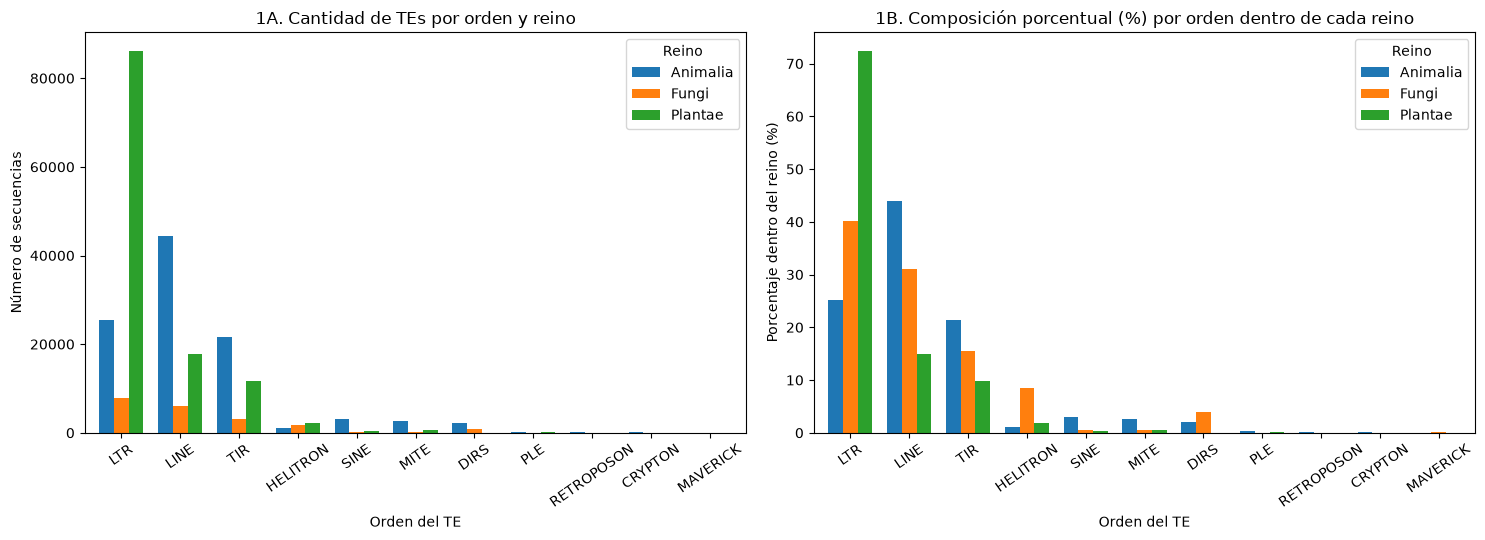

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pathlib import Path

Path("../reports").mkdir(exist_ok=True)

# Pivoteamos el resultado de la Consulta 3A (df_q3_reino)
piv_q3 = df_q3_reino.pivot_table(index="_id.te_order", columns="_id.Kingdom", values="total_tes",
                                 aggfunc="sum", fill_value=0)
# Ordenamos los órdenes de mayor a menor cantidad total
piv_q3 = piv_q3.loc[piv_q3.sum(axis=1).sort_values(ascending=False).index]
piv_q3_pct = piv_q3.div(piv_q3.sum(axis=0), axis=1) * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

piv_q3.plot(kind="bar", ax=axes[0], color=["#1f77b4", "#ff7f0e", "#2ca02c"], width=0.75, rot=35)
axes[0].set_title("1A. Cantidad de TEs por orden y reino")
axes[0].set_xlabel("Orden del TE")
axes[0].set_ylabel("Número de secuencias")
axes[0].legend(title="Reino")

piv_q3_pct.plot(kind="bar", ax=axes[1], color=["#1f77b4", "#ff7f0e", "#2ca02c"], width=0.75, rot=35)
axes[1].set_title("1B. Composición porcentual (%) por orden dentro de cada reino")
axes[1].set_xlabel("Orden del TE")
axes[1].set_ylabel("Porcentaje dentro del reino (%)")
axes[1].legend(title="Reino")

plt.tight_layout()
plt.savefig("../reports/fig1_composicion_reino.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación:** Al expresar los órdenes como porcentaje dentro de cada reino se ve de inmediato que en Plantae más del 72 % de los TEs son retrotransposones LTR (86.049 de 119.005), mientras que en Animalia lideran LINE (~44 %), LTR (~25 %) y TIR (~21 %). Es el mismo patrón de la Consulta 3, pero más fácil de comparar entre reinos de tamaños muy distintos.

### Figura 2: Longitud de los TEs por orden
Diagrama de cajas de la longitud de las secuencias para cada orden de TE, ordenado por la mediana de longitud. Los datos se extraen de MongoDB proyectando solo `te_order` y `metrics.length`.

C:\Users\alejo\AppData\Local\Temp\ipykernel_4132\1574231333.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


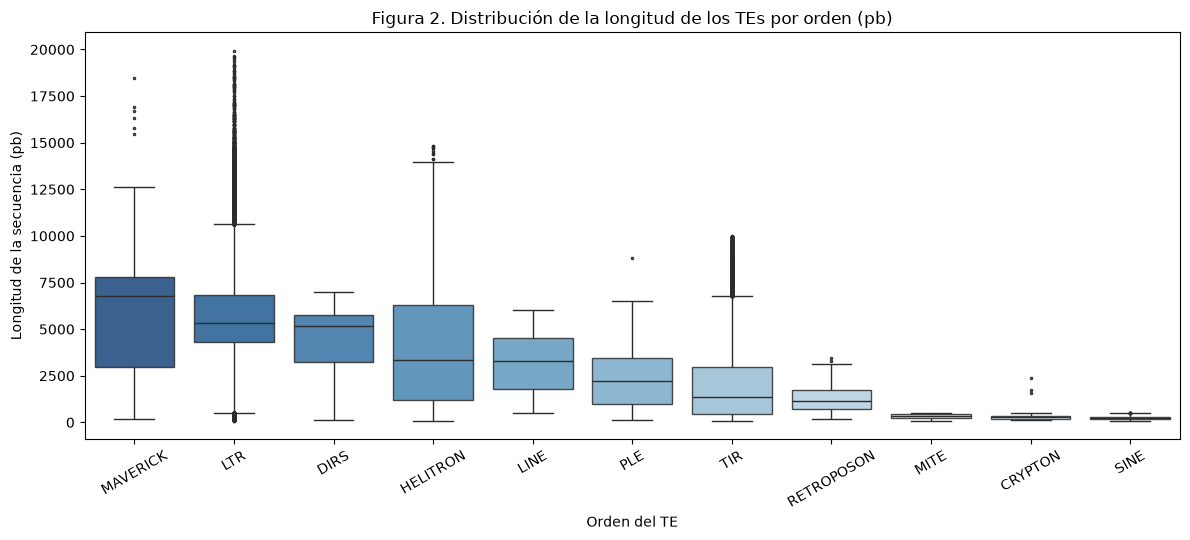

In [20]:
# Extraemos te_order y longitud directamente de MongoDB
docs_len = list(db.sequences.find({}, {"_id": 0, "te_order": 1, "metrics.length": 1}))
df_len = pd.DataFrame([{"te_order": d["te_order"], "length": d["metrics"]["length"]} for d in docs_len])

# Ordenar ejes por mediana de longitud descendente
orden_mediana = df_len.groupby("te_order")["length"].median().sort_values(ascending=False).index

plt.figure(figsize=(12, 5.5))
sns.boxplot(
    data=df_len, x="te_order", y="length", order=orden_mediana,
    palette="Blues_r", fliersize=1.5, boxprops=dict(alpha=0.85)
)
plt.title("Figura 2. Distribución de la longitud de los TEs por orden (pb)")
plt.xlabel("Orden del TE")
plt.ylabel("Longitud de la secuencia (pb)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("../reports/fig2_boxplot_longitud_orden.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación:** Se aprecia la separación entre los retrotransposones autónomos largos y los elementos cortos no autónomos. LTR tiene las medianas más altas (alrededor de 5.000 pb) y extremos cercanos a los 20.000 pb, como vimos en la Consulta 7, mientras que DIRS y LINE se ubican aproximadamente entre 3.000 y 4.500 pb. En el otro extremo, MITE y SINE se concentran por debajo de unos 500 pb.

### Figura 3: Contenido GC entre reinos
A la izquierda, boxplot de la distribución del % GC por reino (mapeando `species_key` → `Kingdom` desde `species`); a la derecha, barras agrupadas del % GC promedio por orden y reino, usando `df_q6` de la Consulta 6.

C:\Users\alejo\AppData\Local\Temp\ipykernel_4132\3056334183.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


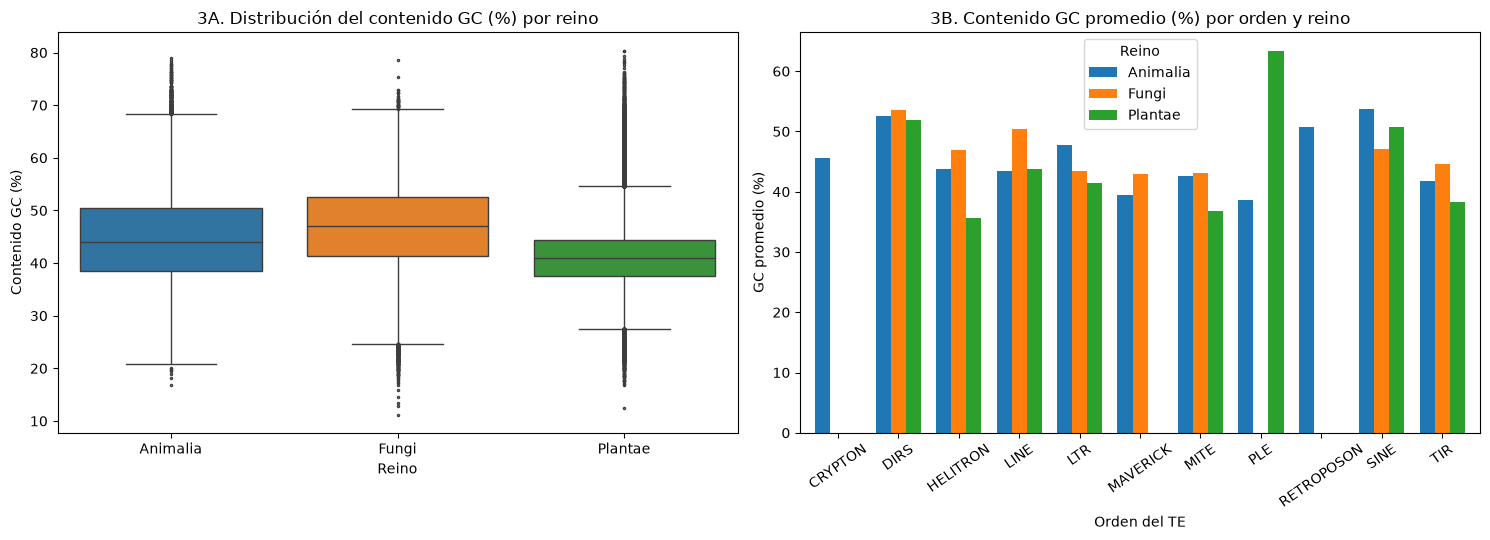

In [21]:
# Mapa rápido species_key -> Kingdom desde la colección species
mapa_reino = {d["species_key"]: d["Kingdom"] for d in db.species.find({}, {"_id": 0, "species_key": 1, "Kingdom": 1})}

docs_gc = list(db.sequences.find({}, {"_id": 0, "species_key": 1, "metrics.gc_content": 1}))
df_gc = pd.DataFrame([
    {"Kingdom": mapa_reino[d["species_key"]], "gc_content": d["metrics"]["gc_content"]}
    for d in docs_gc
])

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# 3A: Boxplot global entre reinos
sns.boxplot(
    data=df_gc, x="Kingdom", y="gc_content", order=["Animalia", "Fungi", "Plantae"],
    palette=["#1f77b4", "#ff7f0e", "#2ca02c"], ax=axes[0], fliersize=1.5
)
axes[0].set_title("3A. Distribución del contenido GC (%) por reino")
axes[0].set_xlabel("Reino")
axes[0].set_ylabel("Contenido GC (%)")

# 3B: Barras del GC promedio por orden y reino (usando df_q6 de la Consulta 6)
piv_gc = df_q6.pivot(index="te_order", columns="Kingdom", values="gc_promedio")
piv_gc.plot(kind="bar", ax=axes[1], color=["#1f77b4", "#ff7f0e", "#2ca02c"], width=0.75, rot=35)
axes[1].set_title("3B. Contenido GC promedio (%) por orden y reino")
axes[1].set_xlabel("Orden del TE")
axes[1].set_ylabel("GC promedio (%)")
axes[1].legend(title="Reino")

plt.tight_layout()
plt.savefig("../reports/fig3_contenido_gc_reinos.png", dpi=150, bbox_inches="tight")
plt.show()

### Figura 4: Frecuencia de los dímeros (k=2) por orden de TE
Mapa de calor con la frecuencia relativa (%) de los 16 dímeros (AA, AC, ..., TT) para cada orden de TE. Se normaliza dentro de cada orden (cada fila suma 100 %) para poder comparar de forma justa órdenes largos, como LTR (~5.000 pb), con cortos, como SINE o MITE (~250 pb). La suma de los 16 campos `kmers.k2.*` se hace en MongoDB con un `$group` por `te_order`, y la normalización en pandas.

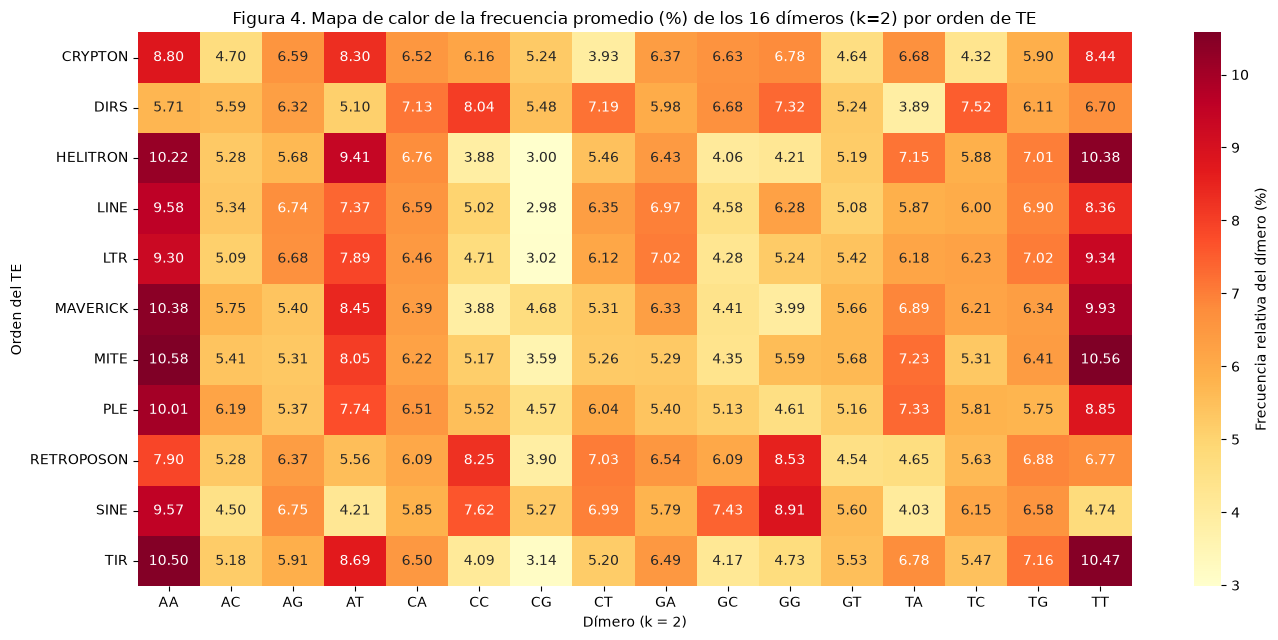

In [22]:
import itertools

dimeros = ["".join(p) for p in itertools.product("ACGT", repeat=2)]

# Construimos dinámicamente el $group en MongoDB para sumar cada uno de los 16 dímeros por te_order
group_k2 = {"_id": "$te_order", "n_seqs": {"$sum": 1}}
for d in dimeros:
    group_k2[d] = {"$sum": f"$kmers.k2.{d}"}

res_k2 = list(db.sequences.aggregate([{"$group": group_k2}, {"$sort": {"_id": 1}}]))
df_k2_raw = pd.DataFrame(res_k2).set_index("_id")

# Frecuencia relativa (%) de cada dímero sobre el total de dímeros del orden (cada fila suma 100 %)
df_k2_rel = df_k2_raw[dimeros].div(df_k2_raw[dimeros].sum(axis=1), axis=0) * 100

plt.figure(figsize=(14, 6.5))
sns.heatmap(
    df_k2_rel, annot=True, fmt=".2f", cmap="YlOrRd",
    cbar_kws={"label": "Frecuencia relativa del dímero (%)"}
)
plt.title("Figura 4. Mapa de calor de la frecuencia promedio (%) de los 16 dímeros (k=2) por orden de TE")
plt.xlabel("Dímero (k = 2)")
plt.ylabel("Orden del TE")
plt.tight_layout()
plt.savefig("../reports/fig4_heatmap_kmers_k2.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación:** Hay dos grupos de perfiles bastante distintos:

- **Perfiles muy parecidos (ricos en A+T):** los órdenes de clase II (HELITRON, TIR y MITE) junto con PLE tienen perfiles casi gemelos, con una fuerte concentración en los dímeros formados por A y T (AA, TT, AT y TA, cada uno por encima de ~8-10 %) y muy pocos CG. Esta escasez de CG podría reflejar la depleción de dinucleótidos CpG asociada a la metilación de citosinas.
- **Perfiles distintos (más equilibrados o ricos en G+C):** órdenes de clase I como SINE, DIRS y RETROPOSON muestran una distribución más uniforme en los dímeros centrales (GC, CG, CC, GG, AG, CT), claramente diferente de la de TIR y HELITRON.

Que los órdenes se separen así por su perfil de k-mers sugiere que estos perfiles son útiles como características para clasificar TEs automáticamente, como se hace en PanTEon.